##### Git

In [ ]:
!git config --global user.name "WalterOuO"
!git config --global user.email "walterlai@gapp.nthu.edu.tw"

In [ ]:
# !git rm -r --cached . # 不要隨便用, 會把過去git紀錄全清空

# 如果要強制修改上一次push的所有file的commit：用--amend，push 尾巴加上 -f
# !git commit --amend -m "Initial Commit"

# 如果上一次push的file只有一個檔案要修改commit:
# !git reset HEAD~1 --soft   # 用 reset 把上一次的紀錄打開: HEAD~1就是上一次, HEAD~2就是上兩次
# !git reset HEAD .      # 把所有檔案先移出暫存區
# !git add .          # 再把上次push的所有檔案加進去
# !git reset somefile     # 唯獨把要修改commit的檔案移出暫存區
# !git commit -m "原本commit" # 把不用改的檔案commit就寫原本commit
# !git add app/.qdrant-initialized # 再把要改的檔案加入暫存區
# !git commit -m "new commit" # 再單獨修改它的新commit
# !git push -u origin main -f # 強制覆蓋線上的錯誤紀錄

In [ ]:
# feat	 新增功能 (Feature)
# fix	  修復 Bug (Bug Fix)
# docs	 僅修改文件 (Documentation)
# style	 不影響程式碼運作的格式調整（如空格、分號、缩排）
# refactor 輸出不變時重構程式碼（既不是新增功能，也不是修補 Bug）
# perf	 效能優化 (Performance)
# test	 增加或修改測試代碼 (Test)
# chore	 建構流程或輔助工具的變動（如 CI/CD、套件版號更新）
# revert	撤銷先前的 commit

In [ ]:
!git add .
!git commit -m "feat: Day 3 automatic prefix caching exp done"
!git push

### 環境初始化

##### 掛載Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/vllm-inference-optimization

Mounted at /content/drive
/content/drive/MyDrive/vllm-inference-optimization


##### 環境檢查

In [2]:
!nvidia-smi

import torch
print(f"CUDA 是否可用: {torch.cuda.is_available()}")
if torch.cuda.is_available():
  print(f"GPU 型號: {torch.cuda.get_device_name(0)}")
  print(f"VRAM 總容量: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Thu Oct 22 16:14:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

##### 安裝依賴套件

In [3]:
!pip install -q -r requirements.txt

print("✅ 所有依賴套件已完成安裝！")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 526.6/526.6 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 58.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 41.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.7/504.7 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 56.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20

### Day 1: model weight AWQ to fp8

##### 執行Baseline實驗

In [ ]:
!python src/experiments/day1_awq_runner.py --mode baseline --config configs/day1_awq.yaml

========== 啟動 Day 1 實驗: BASELINE ==========
模型 ID: Qwen/Qwen2.5-3B-Instruct
Prompt 來源: data/prompts/benchmark_prompts.json
config.json: 100% 661/661 [00:00<00:00, 3.35MB/s]
🔍 [動態模型結構解析] 總參數量: 3.40 B (3,396,861,952 params)
🔍 [動態權重計算] 理論模型權重佔用: 6.33 GB
🚀 成功載入 30 個內容獨立的 Prompts (高併發壓測)
(MainProcess pid=5344) INFO 10-21 14:30:15 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'dtype': 'float16', 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=5344) INFO 10-21 14:30:35 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=5344) WARNING 10-21 14:30:35 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=5344) INFO 10-21 14:30:35 [model.py:2152] Using max model len 32768
(MainProcess pid=5344) INFO 10-21 14:30:35 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
model.safetensors.index.json: 100% 35.6k/35.6k [00:00<00:00, 93.0MB/s]
Parse safete

##### 執行優化實驗

In [ ]:
!python src/experiments/day1_awq_runner.py --mode awq --config configs/day1_awq.yaml

========== 啟動 Day 1 實驗: AWQ ==========
模型 ID: Qwen/Qwen2.5-3B-Instruct-AWQ
Prompt 來源: data/prompts/benchmark_prompts.json
config.json: 100% 839/839 [00:00<00:00, 4.43MB/s]
🔍 [動態模型結構解析] 總參數量: 3.40 B (3,396,861,952 params)
🔍 [動態權重計算] 理論模型權重佔用: 1.82 GB
🚀 成功載入 30 個內容獨立的 Prompts (高併發壓測)
(MainProcess pid=6810) INFO 10-21 14:34:54 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'dtype': 'float16', 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'quantization': 'awq', 'model': 'Qwen/Qwen2.5-3B-Instruct-AWQ'}
(MainProcess pid=6810) INFO 10-21 14:34:56 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=6810) INFO 10-21 14:34:56 [model.py:2152] Using max model len 32768
(MainProcess pid=6810) INFO 10-21 14:34:58 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=6810) INFO 10-21 14:35:02 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_a

##### 生成圖表對比

====================== Day 1 實驗對照總結 ======================
    mode                        model  concurrency  model_weight_vram_gb  kv_cache_pool_vram_gb  total_reserved_vram_gb  system_tps
baseline     Qwen/Qwen2.5-3B-Instruct           30                  6.33                   5.73                   12.06      279.65
     awq Qwen/Qwen2.5-3B-Instruct-AWQ           30                  1.82                  10.26                   12.08      330.54


/tmp/ipykernel_497/1789403144.py:60: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_497/1789403144.py:60: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_497/1789403144.py:62: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/tmp/ipykernel_497/1789403144.py:62: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


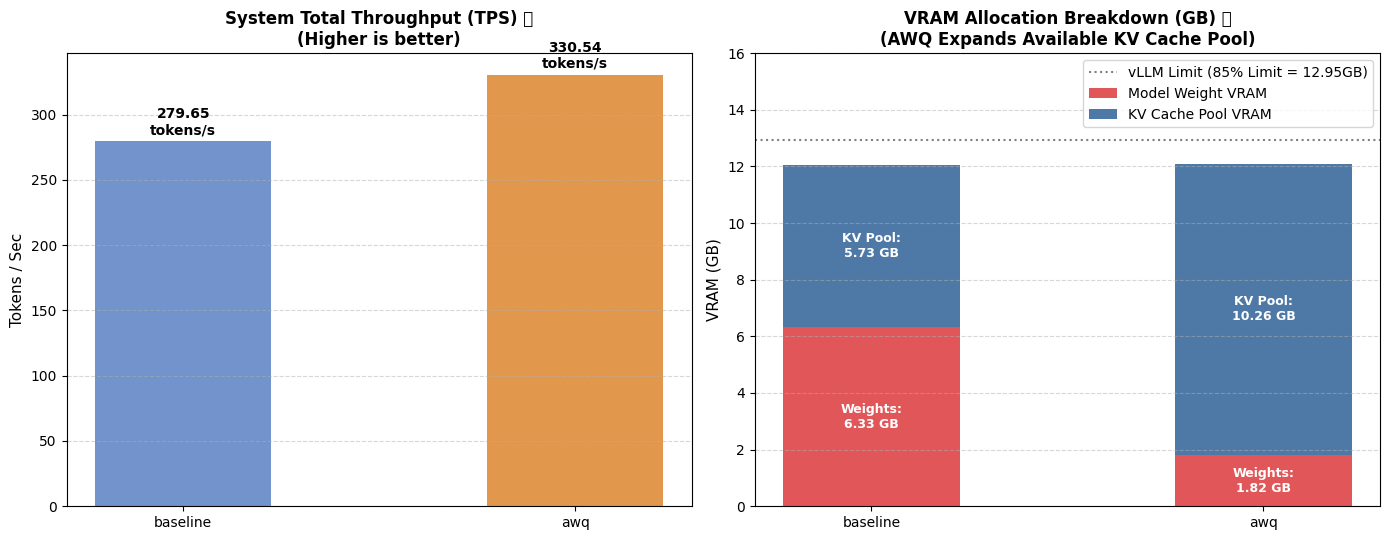


📊 高級視覺化圖表已儲存至: results/charts/day1_awq_comparison.png


In [ ]:
# Cell 7: [Report & Visualization] 生成結構化 VRAM 拆解與 TPS 吞吐量對比圖表

import json
import pandas as pd
import matplotlib.pyplot as plt

# 1. 讀取兩組實驗的 JSON 結果
with open("results/raw_logs/day1_baseline.json", "r", encoding="utf-8") as f:
    baseline_res = json.load(f)

with open("results/raw_logs/day1_awq.json", "r", encoding="utf-8") as f:
    awq_res = json.load(f)

df = pd.DataFrame([baseline_res, awq_res])

# 2. 印出文字版摘要對照表 (包含動態拆解指標)
print("====================== Day 1 實驗對照總結 ======================")
summary_cols = ["mode", "model", "concurrency", "model_weight_vram_gb", "kv_cache_pool_vram_gb", "total_reserved_vram_gb", "system_tps"]
print(df[summary_cols].to_string(index=False))

# 3. 繪製對比圖表 (左圖：TPS 吞吐量 / 右圖：VRAM 堆疊結構)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 圖 1: System TPS 對比 (越大越好)
bars = axes[0].bar(df['mode'], df['system_tps'], color=['#7293CB', '#E1974C'], width=0.45)
axes[0].set_title('System Total Throughput (TPS) 🚀\n(Higher is better)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Tokens / Sec', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height + 3,
                f"{height:.2f}\ntokens/s", ha='center', va='bottom', fontweight='bold')

# 圖 2: VRAM 堆疊結構圖 (顯示模型權重與 KV Cache Pool 的消長)
modes = df['mode']
weight_vram = df['model_weight_vram_gb']
kv_pool_vram = df['kv_cache_pool_vram_gb']

# 繪製堆疊柱狀圖 (Model Weights 在下，KV Cache Pool 在上)
p1 = axes[1].bar(modes, weight_vram, width=0.45, label='Model Weight VRAM', color='#E15759')
p2 = axes[1].bar(modes, kv_pool_vram, width=0.45, bottom=weight_vram, label='KV Cache Pool VRAM', color='#4E79A7')

axes[1].set_title('VRAM Allocation Breakdown (GB) 📊\n(AWQ Expands Available KV Cache Pool)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('VRAM (GB)', fontsize=11)
axes[1].set_ylim(0, 16) # 設定最高為 T4 顯存上限 15-16GB
axes[1].axhline(y=12.95, color='gray', linestyle=':', label='vLLM Limit (85% Limit = 12.95GB)')
axes[1].legend(loc='upper right')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# 在柱狀圖上標註數值
for i in range(len(df)):
    # 標註模型權重 GB
    axes[1].text(i, weight_vram[i]/2, f"Weights:\n{weight_vram[i]} GB",
                 ha='center', va='center', color='white', fontweight='bold', fontsize=9)
    # 標註 KV Cache Pool GB
    axes[1].text(i, weight_vram[i] + kv_pool_vram[i]/2, f"KV Pool:\n{kv_pool_vram[i]} GB",
                 ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
chart_path = "results/charts/day1_awq_comparison.png"
plt.savefig(chart_path, dpi=300)
plt.show()

print(f"\n📊 高級視覺化圖表已儲存至: {chart_path}")

### Day 2: Chunked Prefill
> 因為 T4 GPU不支援把 KV cache從 FP16量化到 FP8

##### 執行 Baseline 實驗

In [ ]:
!python src/experiments/day2_chunked_prefill_runner.py --mode baseline --config configs/day2_chunked_prefill.yaml

🚀 [Day 2 Real Test] 模式: baseline | Chunked Prefill: False | 長度梯度: [2, 4, 8, 16]
(MainProcess pid=16696) INFO 10-21 16:27:33 [api_utils.py:286] non-default args: {'dtype': 'float16', 'max_model_len': 20480, 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'enforce_eager': True, 'enable_chunked_prefill': False, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=16696) INFO 10-21 16:27:33 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=16696) WARNING 10-21 16:27:33 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=16696) INFO 10-21 16:27:33 [model.py:2152] Using max model len 20480
(MainProcess pid=16696) WARNING 10-21 16:27:33 [arg_utils.py:3005] This model does not officially support disabling chunked prefill. Disabling this manually may cause the engine to crash or produce incorrect outputs.
Parse safetensors files: 100% 2/2 [00:00<00:00,  4.72it/s]
(MainProcess pid=16696) WARNING 10-21 16:27:34 [vllm.py:1703] Enforce eager s

##### 執行 KV cache 量化實驗

In [ ]:
!python src/experiments/day2_chunked_prefill_runner.py --mode chunked_prefill --config configs/day2_chunked_prefill.yaml

🚀 [Day 2 Real Test] 模式: chunked_prefill | Chunked Prefill: True | 長度梯度: [2, 4, 8, 16]
(MainProcess pid=18607) INFO 10-21 16:34:40 [api_utils.py:286] non-default args: {'dtype': 'float16', 'max_model_len': 20480, 'gpu_memory_utilization': 0.85, 'max_num_batched_tokens': 2048, 'disable_log_stats': True, 'enforce_eager': True, 'enable_chunked_prefill': True, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=18607) INFO 10-21 16:34:40 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=18607) WARNING 10-21 16:34:40 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=18607) INFO 10-21 16:34:40 [model.py:2152] Using max model len 20480
(MainProcess pid=18607) INFO 10-21 16:34:40 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=2048.
Parse safetensors files: 100% 2/2 [00:00<00:00,  3.96it/s]
(MainProcess pid=18607) WARNING 10-21 16:34:41 [vllm.py:1703] Enforce eager set, disabling torch.compile, CUDAGraphs, and JIT kernel 

##### 生成圖表對比

=================== Day 2: Chunked Prefill 記憶體管理實測總結 ===================
| gradient   |   Prefill Max Tokens (Baseline) |   Prefill Max Tokens (Chunked) |   Active KV VRAM (GB) |   Decode TPS (Baseline) |   Decode TPS (Chunked) |   Latency Baseline (s) |   Latency Chunked (s) |
|:-----------|--------------------------------:|-------------------------------:|----------------------:|------------------------:|-----------------------:|-----------------------:|----------------------:|
| 16K        |                           68576 |                           2048 |                2.3895 |                    4.32 |                   4.46 |                 237.01 |                229.8  |
| 2K         |                            8856 |                           2048 |                0.3392 |                   57.83 |                  58.12 |                  17.71 |                 17.62 |
| 4K         |                           17584 |                           2048 |                0.6389

/tmp/ipykernel_373/381751217.py:69: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_373/381751217.py:69: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_373/381751217.py:70: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/tmp/ipykernel_373/381751217.py:70: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


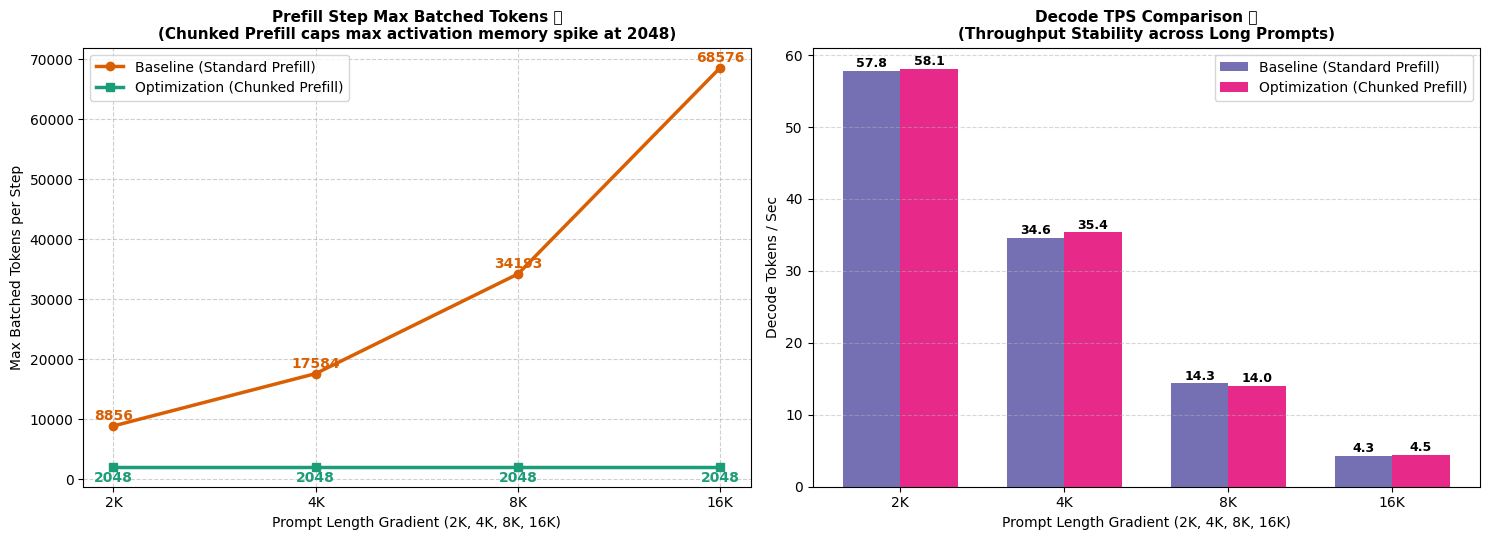


📊 圖表已儲存至: results/charts/day2_chunked_prefill_comparison.png


In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt

# 1. 載入 JSON 數據
with open("results/raw_logs/day2_baseline.json", "r") as f:
    base_data = json.load(f)

with open("results/raw_logs/day2_chunked_prefill.json", "r") as f:
    chunked_data = json.load(f)

df_base = pd.DataFrame(base_data["metrics"]).assign(mode="Baseline (Standard Prefill)")
df_chunked = pd.DataFrame(chunked_data["metrics"]).assign(mode="Optimization (Chunked Prefill)")
df_all = pd.concat([df_base, df_chunked], ignore_index=True)

# 2. 輸出摘要數據表
print("=================== Day 2: Chunked Prefill 記憶體管理實測總結 ===================")
pivot_tokens = df_all.pivot(index="gradient", columns="mode", values="prefill_step_max_tokens")
pivot_kv_vram = df_all.pivot(index="gradient", columns="mode", values="active_kv_vram_gb")
pivot_tps = df_all.pivot(index="gradient", columns="mode", values="decode_tps")
pivot_lat = df_all.pivot(index="gradient", columns="mode", values="latency_sec")

summary_df = pd.DataFrame({
    "Prefill Max Tokens (Baseline)": pivot_tokens["Baseline (Standard Prefill)"],
    "Prefill Max Tokens (Chunked)": pivot_tokens["Optimization (Chunked Prefill)"],
    "Active KV VRAM (GB)": pivot_kv_vram["Baseline (Standard Prefill)"],
    "Decode TPS (Baseline)": pivot_tps["Baseline (Standard Prefill)"],
    "Decode TPS (Chunked)": pivot_tps["Optimization (Chunked Prefill)"],
    "Latency Baseline (s)": pivot_lat["Baseline (Standard Prefill)"],
    "Latency Chunked (s)": pivot_lat["Optimization (Chunked Prefill)"]
})
print(summary_df.to_markdown())

# 3. 繪製圖表
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
x_labels = df_base["gradient"].tolist()

# 圖 1: Prefill 單步 Tokens 峰值 (Chunked Prefill 壓制效果)
axes[0].plot(x_labels, df_base["prefill_step_max_tokens"], marker='o', linewidth=2.5, label="Baseline (Standard Prefill)", color='#D95F02')
axes[0].plot(x_labels, df_chunked["prefill_step_max_tokens"], marker='s', linewidth=2.5, label="Optimization (Chunked Prefill)", color='#1B9E77')
axes[0].set_title('Prefill Step Max Batched Tokens 📉\n(Chunked Prefill caps max activation memory spike at 2048)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Prompt Length Gradient (2K, 4K, 8K, 16K)')
axes[0].set_ylabel('Max Batched Tokens per Step')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

for i, (v1, v2) in enumerate(zip(df_base["prefill_step_max_tokens"], df_chunked["prefill_step_max_tokens"])):
    axes[0].text(i, v1 + 1000, f"{v1}", ha='center', color='#D95F02', fontweight='bold')
    axes[0].text(i, v2 - 2500 if v2 < v1 else v2 + 1000, f"{v2}", ha='center', color='#1B9E77', fontweight='bold')

# 圖 2: Decode TPS 對比
x = range(len(x_labels))
width = 0.35
axes[1].bar([p - width/2 for p in x], df_base["decode_tps"], width, label="Baseline (Standard Prefill)", color='#7570B3')
axes[1].bar([p + width/2 for p in x], df_chunked["decode_tps"], width, label="Optimization (Chunked Prefill)", color='#E7298A')
axes[1].set_title('Decode TPS Comparison 🚀\n(Throughput Stability across Long Prompts)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Prompt Length Gradient (2K, 4K, 8K, 16K)')
axes[1].set_ylabel('Decode Tokens / Sec')
axes[1].set_xticks(x)
axes[1].set_xticklabels(x_labels)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend()

for i, (v1, v2) in enumerate(zip(df_base["decode_tps"], df_chunked["decode_tps"])):
    axes[1].text(i - width/2, v1 + 0.5, f"{v1:.1f}", ha='center', fontsize=9, fontweight='bold')
    axes[1].text(i + width/2, v2 + 0.5, f"{v2:.1f}", ha='center', fontsize=9, fontweight='bold')

chart_path = "results/charts/day2_chunked_prefill_comparison.png"
plt.tight_layout()
plt.savefig(chart_path, dpi=300)
plt.show()

print(f"\n📊 圖表已儲存至: {chart_path}")

### Day 3 : KV cache reuse (prefix caching)

##### 執行 Baseline 實驗

In [ ]:
!python src/experiments/day3_prefix_caching_runner.py --mode baseline --config configs/day3_prefix_caching.yaml

✅ 已成功構建 5 個請求數據集 (data/prompts/day3_dataset.jsonl)：共用 2K System Prompt + 5 個獨立 User Questions
🚀 啟動 vLLM Server (BASELINE 模式, 旗標: --no-enable-prefix-caching)...
📝 伺服器啟動日誌同步寫入: results/logs/vllm_server_baseline.log
✅ vLLM Server 已順利啟動完成！

📢 執行 vLLM 官方 'vllm bench serve' 線上測試...

==================== vLLM Bench Serve 官方線上測試報告 ====================
Namespace(subparser='bench', bench_type='serve', dispatch_function=<function BenchmarkServingSubcommand.cmd at 0x7be9838ccae0>, trust_remote_code=False, seed=0, num_prompts=5, dataset_name='custom', no_stream=False, dataset_path='data/prompts/day3_dataset.jsonl', no_oversample=False, skip_chat_template=False, enable_multimodal_chat=False, disable_shuffle=False, custom_output_len=256, custom_ensure_client_side_data=False, spec_bench_output_len=256, spec_bench_category=None, sharegpt_output_len=None, timed_trace_chunk_hash_size=16, timed_trace_sec_multiplier=1, timed_trace_label_timestamp='timestamp', timed_trace_label_input_length='input_length', 

##### 執行優化實驗

In [ ]:
!python src/experiments/day3_prefix_caching_runner.py --mode apc --config configs/day3_prefix_caching.yaml

✅ 已成功構建 5 個請求數據集 (data/prompts/day3_dataset.jsonl)：共用 2K System Prompt + 5 個獨立 User Questions
🚀 啟動 vLLM Server (APC 模式, 旗標: --enable-prefix-caching)...
📝 伺服器啟動日誌同步寫入: results/logs/vllm_server_apc.log
✅ vLLM Server 已順利啟動完成！

📢 執行 vLLM 官方 'vllm bench serve' 線上測試...

==================== vLLM Bench Serve 官方線上測試報告 ====================
Namespace(subparser='bench', bench_type='serve', dispatch_function=<function BenchmarkServingSubcommand.cmd at 0x7d0dc04785e0>, trust_remote_code=False, seed=0, num_prompts=5, dataset_name='custom', no_stream=False, dataset_path='data/prompts/day3_dataset.jsonl', no_oversample=False, skip_chat_template=False, enable_multimodal_chat=False, disable_shuffle=False, custom_output_len=256, custom_ensure_client_side_data=False, spec_bench_output_len=256, spec_bench_category=None, sharegpt_output_len=None, timed_trace_chunk_hash_size=16, timed_trace_sec_multiplier=1, timed_trace_label_timestamp='timestamp', timed_trace_label_input_length='input_length', timed_trace_l

##### 生成對比圖表

====================== Day 3 實驗結果總結 ======================
             Mode  TTFT Avg (ms)  TTFT P99 (ms) Cache Hits / Queries Cache Hit Rate (%)
Baseline (No APC)        7388.60        8560.20                0 / 0               0.0%
      APC Enabled         827.25        1804.98         8512 / 11196             76.03%


/tmp/ipykernel_533/529275840.py:61: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_533/529275840.py:61: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_533/529275840.py:64: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/tmp/ipykernel_533/529275840.py:64: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


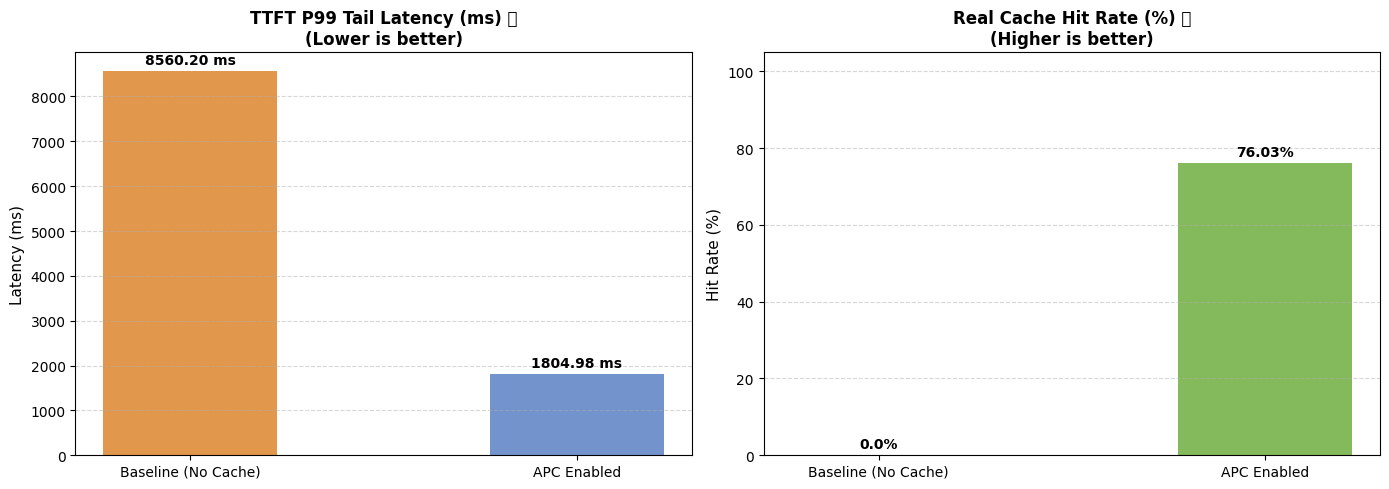


📊 圖表已成功儲存至: results/charts/day3_apc_comparison.png


In [ ]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# 1. 讀取 JSON 結果
with open("results/raw_logs/day3_baseline.json", "r", encoding="utf-8") as f:
    base_res = json.load(f)

with open("results/raw_logs/day3_apc.json", "r", encoding="utf-8") as f:
    apc_res = json.load(f)

# 2. 輸出文字版摘要對照表
df_summary = pd.DataFrame([
    {
        "Mode": "Baseline (No APC)",
        "TTFT Avg (ms)": base_res["ttft_avg_ms"] if base_res["ttft_avg_ms"] is not None else "請參閱主機 stdout",
        "TTFT P99 (ms)": base_res["ttft_p99_ms"] if base_res["ttft_p99_ms"] is not None else "請參閱主機 stdout",
        "Cache Hits / Queries": f"{base_res['cache_hits']} / {base_res['cache_queries']}",
        "Cache Hit Rate (%)": f"{base_res['cache_hit_rate_pct']}%"
    },
    {
        "Mode": "APC Enabled",
        "TTFT Avg (ms)": apc_res["ttft_avg_ms"] if apc_res["ttft_avg_ms"] is not None else "請參閱主機 stdout",
        "TTFT P99 (ms)": apc_res["ttft_p99_ms"] if apc_res["ttft_p99_ms"] is not None else "請參閱主機 stdout",
        "Cache Hits / Queries": f"{apc_res['cache_hits']} / {apc_res['cache_queries']}",
        "Cache Hit Rate (%)": f"{apc_res['cache_hit_rate_pct']}%"
    }
])

print("====================== Day 3 實驗結果總結 ======================")
print(df_summary.to_string(index=False))

# 3. 繪製對比圖表
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
modes = ['Baseline (No Cache)', 'APC Enabled']

# (A) TTFT P99 尾端延遲比較
p99_base = base_res["ttft_p99_ms"] if isinstance(base_res["ttft_p99_ms"], (int, float)) else 0
p99_apc = apc_res["ttft_p99_ms"] if isinstance(apc_res["ttft_p99_ms"], (int, float)) else 0
p99_values = [p99_base, p99_apc]

axes[0].bar(modes, p99_values, color=['#E1974C', '#7293CB'], width=0.45)
axes[0].set_title('TTFT P99 Tail Latency (ms) 📉\n(Lower is better)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Latency (ms)', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
for i, v in enumerate(p99_values):
    if v > 0:
        axes[0].text(i, v + (max(p99_values)*0.02 if max(p99_values) > 0 else 1), f"{v:.2f} ms", ha='center', fontweight='bold')

# (B) 真實快取命中率 (Cache Hit Rate %)
hit_rates = [base_res["cache_hit_rate_pct"], apc_res["cache_hit_rate_pct"]]
axes[1].bar(modes, hit_rates, color=['#E1974C', '#84BA5B'], width=0.45)
axes[1].set_title('Real Cache Hit Rate (%) 🎯\n(Higher is better)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Hit Rate (%)', fontsize=11)
axes[1].set_ylim(0, 105)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
for i, v in enumerate(hit_rates):
    axes[1].text(i, v + 2, f"{v}%", ha='center', fontweight='bold')

plt.tight_layout()
os.makedirs("results/charts", exist_ok=True)
chart_path = "results/charts/day3_apc_comparison.png"
plt.savefig(chart_path, dpi=300)
plt.show()

print(f"\n📊 圖表已成功儲存至: {chart_path}")

### Day 4: KV cache offloading

##### 檢查 vllm版本與使用的引擎(V0 / V1)

In [4]:
import os
import importlib.metadata

# 1. 查看 vLLM 版本
try:
    vllm_version = importlib.metadata.version("vllm")
    print(f"vLLM 版本: {vllm_version}")
except Exception as e:
    print(f"無法讀取版本: {e}")

# 2. 查看使用的引擎 (依據環境變數 VLLM_USE_V1)
v1_env = os.environ.get("VLLM_USE_V1", "0")
print(f"目前引擎設定: {'V1 引擎' if v1_env == '1' else 'V0 引擎'}")

vLLM 版本: 0.32.0
目前引擎設定: V0 引擎


##### 執行 Baseline 實驗

In [5]:
!python src/experiments/day4_offload_runner.py --mode baseline --config configs/day4_kv_offloading.yaml

\n==================================================
🚀 [Day 4] Mode: BASELINE | Chunked KV Allocation: False
config.json: 100% 661/661 [00:00<00:00, 2.67MB/s]
(MainProcess pid=2159) INFO 10-22 16:19:24 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'max_model_len': 14000, 'gpu_memory_utilization': 0.65, 'disable_log_stats': True, 'enforce_eager': True, 'enable_chunked_prefill': False, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=2159) WARNING 10-22 16:19:24 [interface.py:1457] Unknown vLLM environment variable detected: VLLM_USE_V1
(MainProcess pid=2159) INFO 10-22 16:19:44 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=2159) WARNING 10-22 16:19:44 [model.py:2439] Your device 'Tesla T4' (with compute capability 7.5) doesn't support torch.bfloat16. Falling back to torch.float16 for compatibility.
(MainProcess pid=2159) WARNING 10-22 16:19:44 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=2159) INFO 10-22 16:1

##### 執行優化實驗

In [6]:
!python src/experiments/day4_offload_runner.py --mode offload --config configs/day4_kv_offloading.yaml

\n==================================================
🚀 [Day 4] Mode: OFFLOAD | Chunked KV Allocation: True
(MainProcess pid=4487) INFO 10-22 16:27:51 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'max_model_len': 14000, 'gpu_memory_utilization': 0.65, 'max_num_batched_tokens': 2048, 'disable_log_stats': True, 'enforce_eager': True, 'enable_chunked_prefill': True, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=4487) WARNING 10-22 16:27:51 [interface.py:1457] Unknown vLLM environment variable detected: VLLM_USE_V1
(MainProcess pid=4487) INFO 10-22 16:27:51 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=4487) WARNING 10-22 16:27:51 [model.py:2439] Your device 'Tesla T4' (with compute capability 7.5) doesn't support torch.bfloat16. Falling back to torch.float16 for compatibility.
(MainProcess pid=4487) WARNING 10-22 16:27:51 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=4487) INFO 10-22 16:27:51 [model.py:2152] 

##### 生成對比圖表

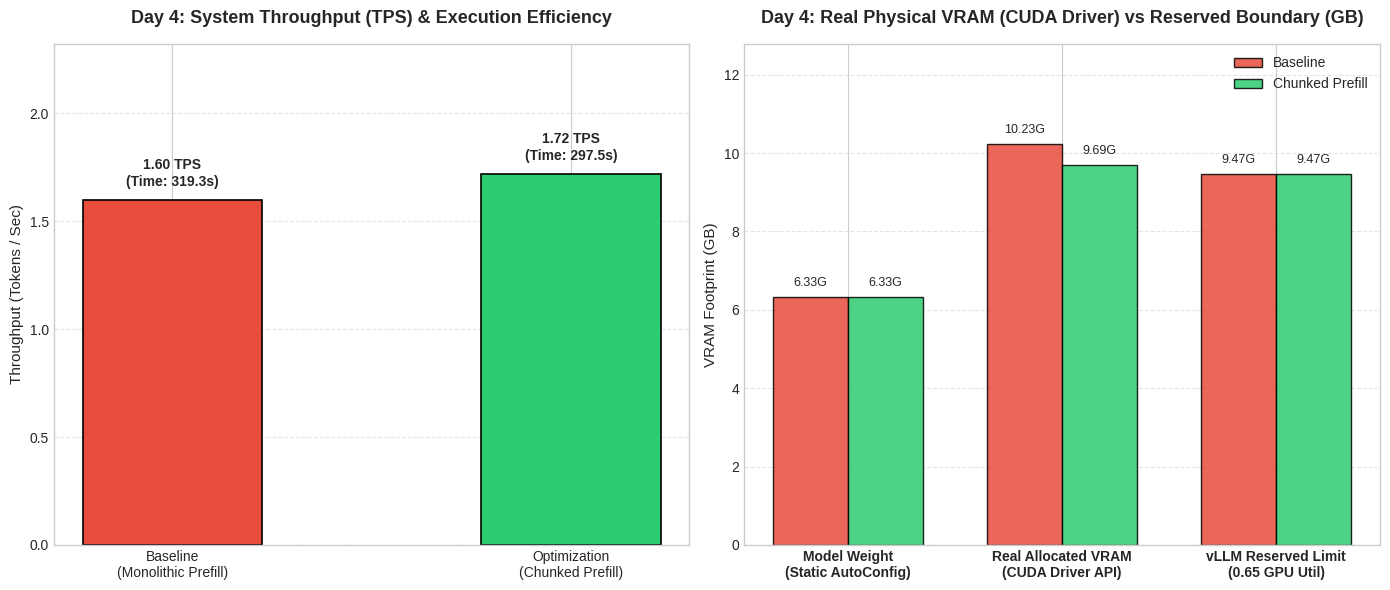

📊 高級視覺化對比圖表已成功繪製並儲存至: results/charts/day4_offloading_benchmark.png


In [7]:
import json
import matplotlib.pyplot as plt
import numpy as np

# 1. 讀取兩組實驗結果 JSON
with open("results/raw_logs/day4_baseline.json", "r", encoding="utf-8") as f:
    base_data = json.load(f)
with open("results/raw_logs/day4_offload.json", "r", encoding="utf-8") as f:
    opt_data = json.load(f)

# 2. 設定繪圖風格
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

modes = ["Baseline\n(Monolithic Prefill)", "Optimization\n(Chunked Prefill)"]

# --- 圖 1: System Throughput (TPS) & Total Execution Time ---
tps_values = [base_data["throughput_tps"], opt_data["throughput_tps"]]
time_values = [base_data["elapsed_time_s"], opt_data["elapsed_time_s"]]
colors = ["#e74c3c", "#2ecc71"]

bars = ax1.bar(modes, tps_values, color=colors, width=0.45, edgecolor="black", linewidth=1.2)
ax1.set_title("Day 4: System Throughput (TPS) & Execution Efficiency", fontsize=13, fontweight="bold", pad=15)
ax1.set_ylabel("Throughput (Tokens / Sec)", fontsize=11)

# 動態調整 Y 軸上限，預留 35% 空間避開標題重疊
max_tps = max(tps_values) if max(tps_values) > 0 else 1.0
ax1.set_ylim(0, max_tps * 1.35)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar, tps, t_sec in zip(bars, tps_values, time_values):
    ax1.text(
        bar.get_x() + bar.get_width() / 2.0,
        tps + (max_tps * 0.03),
        f"{tps:.2f} TPS\n(Time: {t_sec:.1f}s)",
        ha="center", va="bottom", fontsize=10, fontweight="bold"
    )

# --- 圖 2: Real Physical VRAM (CUDA Driver API) vs Reserved Boundary (GB) ---
categories = ["Model Weight\n(Static AutoConfig)", "Real Allocated VRAM\n(CUDA Driver API)", "vLLM Reserved Limit\n(0.65 GPU Util)"]
baseline_mem = [base_data["model_vram_gb"], base_data["measured_physical_vram_gb"], base_data["gpu_reserved_limit_gb"]]
offload_mem = [opt_data["model_vram_gb"], opt_data["measured_physical_vram_gb"], opt_data["gpu_reserved_limit_gb"]]

x = np.arange(len(categories))
width = 0.35

rects1 = ax2.bar(x - width/2, baseline_mem, width, label="Baseline", color="#e74c3c", alpha=0.85, edgecolor="black")
rects2 = ax2.bar(x + width/2, offload_mem, width, label="Chunked Prefill", color="#2ecc71", alpha=0.85, edgecolor="black")

ax2.set_title("Day 4: Real Physical VRAM (CUDA Driver) vs Reserved Boundary (GB)", fontsize=13, fontweight="bold", pad=15)
ax2.set_ylabel("VRAM Footprint (GB)", fontsize=11)
ax2.set_xticks(x)
ax2.set_xticklabels(categories, fontsize=10, fontweight="bold")

max_mem = max(max(baseline_mem), max(offload_mem)) if max(baseline_mem) > 0 else 10.0
ax2.set_ylim(0, max_mem * 1.25)
ax2.legend(loc="upper right")
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for rect in rects1:
    height = rect.get_height()
    ax2.text(rect.get_x() + rect.get_width()/2.0, height + (max_mem * 0.02), f"{height:.2f}G", ha="center", va="bottom", fontsize=9)

for rect in rects2:
    height = rect.get_height()
    ax2.text(rect.get_x() + rect.get_width()/2.0, height + (max_mem * 0.02), f"{height:.2f}G", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
chart_path = "results/charts/day4_offloading_benchmark.png"
plt.savefig(chart_path, dpi=300)
plt.show()

print(f"📊 高級視覺化對比圖表已成功繪製並儲存至: {chart_path}")